## Project Overview and Objective

Compare three classifiers of 2015 forest persistence, conversion to agriculture and conversion to built-up land. Parcel IDs are the reporting regions. Evaluate on unseen parcels from 2015–2025, then rank all original forest parcels using predictions made without their own outcome. One decade of observations supports retrospective screening.

Run beside `land_use_change.csv` with the package versions recorded in the metadata. Running all cells generates the model, metadata, report, ranking and figures.

## Dataset Loading and Inspection

Load the sole source file, record its fingerprint and inspect the actual columns and summary statistics.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import json
import joblib
from IPython.display import display, Markdown

SEED = 42
path = Path("land_use_change.csv")
source_hash = hashlib.sha256(path.read_bytes()).hexdigest()
artifacts = Path("forest_conversion_results")
plots = artifacts / "plots"
plots.mkdir(parents=True, exist_ok=True)
def save_plot(name):
    plt.gcf().savefig(plots / f"{name}.png", dpi=180, bbox_inches="tight")

df = pd.read_csv(path, dtype={"parcel_id": "string"})
base = ["dist_to_city_km", "dist_to_road_km", "slope_deg", "rainfall_mm",
        "soil_quality_idx", "ndvi_2015"]
status = "protected_area"
required = base + [status, "parcel_id", "land_use_2015", "land_use_2025",
                   "population_growth_pct", "changed"]
if missing := sorted(set(required) - set(df)):
    raise ValueError(f"Missing source columns: {missing}")
if df.parcel_id.isna().any() or df.parcel_id.duplicated().any():
    raise ValueError("Expected one nonmissing identifier per parcel.")
print("Source dimensions:", df.shape)
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
display(df.describe(include="all").T)
print("Environment:", {p: metadata.version(p) for p in
                       ["pandas", "numpy", "scikit-learn", "xgboost", "shap", "matplotlib"]})
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 105})
colors = ["#246857", "#ba731c", "#5269aa"]

Source dimensions: (1000, 12)


,dtype,missing
parcel_id,string,0
land_use_2015,str,0
dist_to_city_km,float64,0
dist_to_road_km,float64,0
population_growth_pct,float64,0
slope_deg,float64,0
rainfall_mm,float64,0
soil_quality_idx,float64,0
protected_area,int64,0
ndvi_2015,float64,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
parcel_id,1000,1000,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
land_use_2015,1000,6,Cropland,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dist_to_city_km,1000.0,NaN,NaN,NaN,15.3232,10.728561,0.4,7.3,13.0,21.0,73.2
dist_to_road_km,1000.0,NaN,NaN,NaN,4.98329,3.788,0.05,2.3175,4.09,6.62,37.53
population_growth_pct,1000.0,NaN,NaN,NaN,1.48802,0.997019,-1.46,0.83,1.5,2.1625,5.0
slope_deg,1000.0,NaN,NaN,NaN,10.1317,7.343929,0.2,4.8,8.2,13.5,45.0
rainfall_mm,1000.0,NaN,NaN,NaN,1290.186,355.902096,300.0,1047.5,1272.0,1540.5,2292.0
soil_quality_idx,1000.0,NaN,NaN,NaN,0.51287,0.290893,0.0,0.25,0.52,0.77,1.0
protected_area,1000.0,NaN,NaN,NaN,0.161,0.367715,0.0,0.0,0.0,0.0,1.0
ndvi_2015,1000.0,NaN,NaN,NaN,0.627101,0.170897,0.114,0.512,0.644,0.75325,0.997


Environment: {'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'shap': '0.54.1', 'matplotlib': '3.11.2'}


## Data Quality Analysis

Count missing values and check parcel identifiers before matching outcomes or assigning folds. The shape check identifies changes to the hackathon source.

In [2]:
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()})
quality.to_csv(artifacts / "data_quality.csv")
df.describe(include="all").T.to_csv(artifacts / "source_summary.csv")
assert df.shape == (1000, 12), "Review a changed source before comparing old results."

display(quality)

,dtype,missing
parcel_id,string,0
land_use_2015,str,0
dist_to_city_km,float64,0
dist_to_road_km,float64,0
population_growth_pct,float64,0
slope_deg,float64,0
rainfall_mm,float64,0
soil_quality_idx,float64,0
protected_area,int64,0
ndvi_2015,float64,0


## Column Identification and Assumptions

The key is `parcel_id`. The year comes from `land_use_2015` and `land_use_2025`. The former selects the forest population and the latter supplies the observed destination. Only `ndvi_2015` explicitly dates a predictor. Assume road and city distances, rainfall and protected status describe baseline conditions, and that slope and soil quality are sufficiently stable. Unknown measurement dates could affect the results.

Population growth has an unknown measurement window. It is descriptive only. The model excludes IDs, both land-use columns, the target and the outcome flag `changed`. Road proximity is a single measurement. Infrastructure change cannot be measured here.

## Land-Cover Transition Analysis

Count each observed origin and destination pair across all parcels. Cell annotations preserve counts for rare transitions.

land_use_2025,barren,built-up,cropland,forest,grassland,wetland,All
land_use_2015,,,,,,,
barren,66,22,5,0,3,0,96
built-up,0,86,2,0,0,0,88
cropland,0,37,257,3,3,0,300
forest,2,16,29,230,8,0,285
grassland,5,16,29,4,114,3,171
wetland,1,11,3,1,2,42,60
All,74,188,325,238,130,45,1000


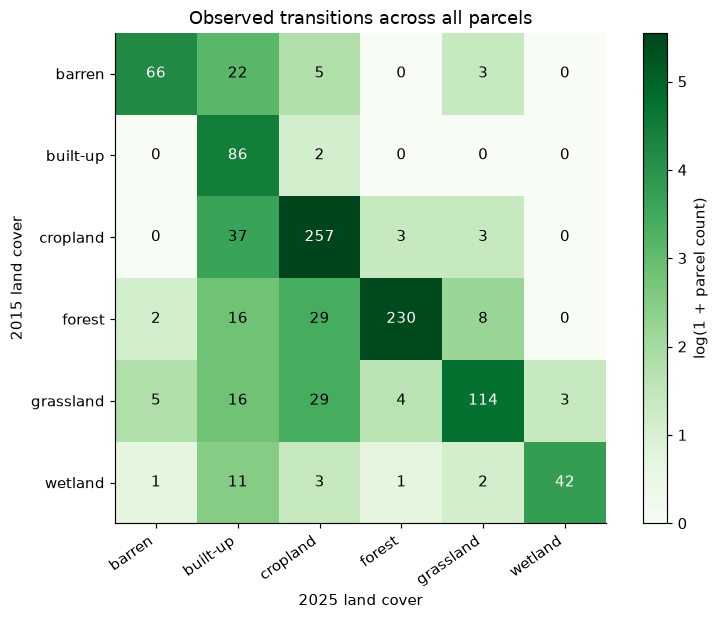

In [3]:
# Normalize spelling and whitespace without assigning unknown categories to a class.
def clean_cover(column):
    return df[column].astype("string").str.strip().str.lower().replace("", pd.NA)

start, end = clean_cover("land_use_2015"), clean_cover("land_use_2025")
display(pd.crosstab(start.fillna("missing"), end.fillna("missing"), margins=True))

transitions = pd.crosstab(start, end)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(np.log1p(transitions), cmap="Greens")
ax.set_xticks(range(len(transitions.columns)), transitions.columns, rotation=35, ha="right")
ax.set_yticks(range(len(transitions)), transitions.index)
for i, j in np.ndindex(transitions.shape):
    n = transitions.iloc[i,j]
    ax.text(j, i, str(n), ha="center", va="center", color="white" if n > 40 else "black")
ax.set(xlabel="2025 land cover", ylabel="2015 land cover", title="Observed transitions across all parcels")
fig.colorbar(im, ax=ax, label="log(1 + parcel count)")
fig.tight_layout()
save_plot("11_transition_matrix")
plt.show()

## Forest Parcel Selection

Keep every parcel recorded as forest in 2015. This set defines the population for the ranked export.

In [4]:
forest = df.loc[start.eq("forest").fillna(False)].copy()
destination = end.loc[forest.index].fillna("missing")

print(len(forest), 'original forest parcels')

285 original forest parcels


## Target Engineering

Map forest, cropland and built-up to three labels. Grassland and barren destinations have no training target. Built-up combines residential and industrial development.

In [5]:
classes = ["no_change", "to_agricultural", "to_built_up"]
forest["target"] = destination.map(dict(zip(["forest", "cropland", "built-up"], classes)))
eligible = forest.target.notna()
y = forest.loc[eligible, "target"].map(dict(zip(classes, range(3)))).astype(int)
codes = np.arange(3)
observed = destination.value_counts()
print("Forest parcels:", len(forest), "| Eligible:", len(y))
display(observed.rename("observed destinations").to_frame())
display(destination[~eligible].value_counts().rename("excluded destinations").to_frame())

assert observed.to_dict() == {"forest": 230, "cropland": 29, "built-up": 16, "grassland": 8, "barren": 2}
assert len(forest) == 285 and len(y) == 275
observed.rename("parcels").to_csv(artifacts / "observed_forest_transitions.csv")
pd.crosstab(start, end).to_csv(artifacts / "all_land_cover_transitions.csv")

Forest parcels: 285 | Eligible: 275


,observed destinations
land_use_2025,
forest,230
cropland,29
built-up,16
grassland,8
barren,2


,excluded destinations
land_use_2025,
grassland,8
barren,2


## Exploratory Data Analysis

Compare land cover across the full dataset and inspect the labelled classes. The forest destination chart includes out-of-scope transitions.

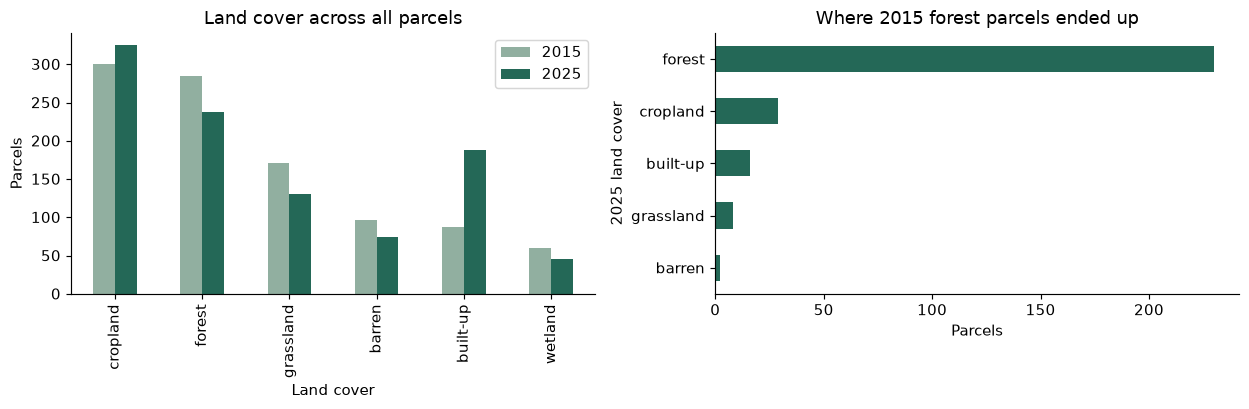

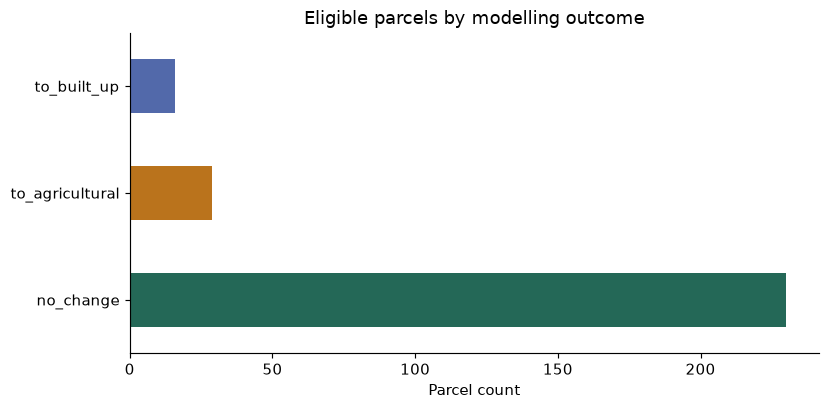

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.concat([start.value_counts(), end.value_counts()], axis=1,
          keys=["2015", "2025"]).fillna(0).plot.bar(ax=axes[0], color=["#91afa0", colors[0]])
axes[0].set(title="Land cover across all parcels", ylabel="Parcels", xlabel="Land cover")
observed.sort_values().plot.barh(ax=axes[1], color=colors[0])
axes[1].set(title="Where 2015 forest parcels ended up", xlabel="Parcels", ylabel="2025 land cover")
fig.tight_layout()
save_plot("01_land_cover_and_forest_transitions")
plt.show()
y.value_counts().reindex(codes).set_axis(classes).plot.barh(color=colors)
plt.title("Eligible parcels by modelling outcome")
plt.xlabel("Parcel count")
plt.tight_layout()
save_plot("03_target_distribution")
plt.show()

## Feature Engineering

Road accessibility increases as road distance falls. It measures proximity at one point in time. Infrastructure change would require repeated measurements. Soil suitability combines soil quality and a slope penalty capped through clipping. This is an unvalidated heuristic. Both proxies reuse baseline measurements, so related features may share importance.

The feature list excludes parcel ID, both land-use labels, the outcome flag and the undated growth rate. Correlations below describe eligible parcels and include the observed binary conversion indicator for context.

Predictors: ['dist_to_city_km', 'dist_to_road_km', 'slope_deg', 'rainfall_mm', 'soil_quality_idx', 'ndvi_2015', 'soil_suitability', 'road_accessibility', 'protected_area']


,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
no_change,230.0,1.420913,0.955644,-1.43,0.8425,1.490,2.0450,3.64
to_agricultural,29.0,1.727931,1.033453,0.12,1.1700,1.700,2.1400,4.39
to_built_up,16.0,1.652500,1.136236,-0.65,0.8075,1.595,2.6775,3.27


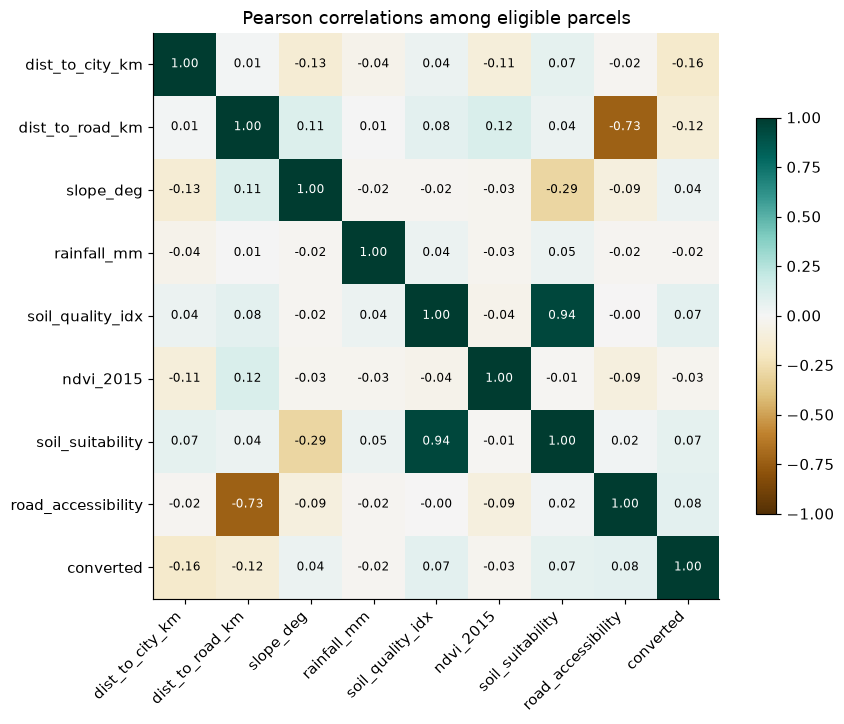

In [7]:
for col in base + ["population_growth_pct"]:
    forest[col] = pd.to_numeric(forest[col], errors="raise").replace([np.inf, -np.inf], np.nan)
if forest.dist_to_road_km.lt(0).any():
    raise ValueError("Road distance must be nonnegative.")
forest["soil_suitability"] = (forest.soil_quality_idx * (1 - forest.slope_deg / 45)).clip(0, 1)
forest["road_accessibility"] = 1 / (1 + forest.dist_to_road_km)
numeric = base + ["soil_suitability", "road_accessibility"]
features = numeric + [status]
X = forest[features].copy()
X[status] = X[status].astype("string").astype(object).where(X[status].notna(), np.nan)
print("Predictors:", features)
display(forest.groupby("target")["population_growth_pct"].describe())
# The heatmap uses numeric predictors; protected status is encoded later as categorical.
corr = forest.loc[y.index, numeric].assign(converted=y.ne(0).astype(int)).corr()
fig, ax = plt.subplots(figsize=(8.7, 7))
im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i, j in np.ndindex(corr.shape):
    ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8,
            color="white" if abs(corr.iloc[i,j]) > .65 else "black")
ax.set_title("Pearson correlations among eligible parcels")
fig.colorbar(im, ax=ax, shrink=.7)
fig.tight_layout()
save_plot("02_feature_correlations")
plt.show()
assert not set(features) & {"parcel_id", "land_use_2015", "land_use_2025", "changed",
                            "target", "population_growth_pct"}
forest.groupby("target")["population_growth_pct"].describe().to_csv(artifacts / "undated_growth_descriptive.csv")

## Data Preprocessing

Define the transformations here and fit them inside each training fold. Use the median and standard scaling for numbers, and most-frequent imputation and one-hot encoding for protected status. Unknown categories receive zero indicator values.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, roc_auc_score, roc_curve,
                             make_scorer)
from xgboost import XGBClassifier


from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score
transform = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler()), numeric),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent", keep_empty_features=True),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False)), [status])
], verbose_feature_names_out=False)

## Train/test split

The original stratified parcel split preserves comparability across experiments. The training folds determine model settings. Earlier runs inspected the holdout, so it cannot serve as a fresh independent test.

In [9]:
train, test = train_test_split(y.index.to_numpy(), test_size=.2, stratify=y, random_state=SEED)
split_counts = pd.DataFrame({"train": y.loc[train].value_counts(), "test": y.loc[test].value_counts()}).reindex(codes)
if split_counts.fillna(0).min().min() < 1:
    raise ValueError("Each outcome needs examples in both splits.")
display(split_counts.set_axis(classes))

assert len(train) == 220 and len(test) == 55 and not set(train) & set(test)
assert len(train)==220 and len(test)==55 and set(train).isdisjoint(test)

,train,test
no_change,184,46
to_agricultural,23,6
to_built_up,13,3


## Repeated cross-validation and tuning

Use the same four stratified folds at each of three fixed seeds for every candidate. Seeds measure sensitivity. All preprocessing, optional PCA and imbalance weights are fitted inside the training fold. The selection score weights macro-F1 and accuracy equally at 40% each and balanced accuracy at 20%. Require nonzero mean recall for both conversion classes when selecting the winner. Break ties by log loss, then fit time.

In [10]:
from time import perf_counter
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
from forest_pipeline import ForestPipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.decomposition import PCA
from sklearn.metrics import recall_score, precision_score, log_loss, average_precision_score
from sklearn.calibration import CalibratedClassifierCV

splits = [split for seed in (42, 73, 109)
          for split in StratifiedKFold(4, shuffle=True, random_state=seed).split(X.loc[train], y.loc[train])]
families = {
    "Logistic Regression": (LogisticRegression(max_iter=2000), {"model__C":[.1, 1.], "reduce":["passthrough",PCA(n_components=.95)]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {"model__max_depth":[2,4], "model__min_samples_leaf":[5,12]}),
    "Random Forest": (RandomForestClassifier(n_estimators=100,n_jobs=1,random_state=SEED), {"model__max_depth":[4,8],"model__min_samples_leaf":[3,8]}),
    "Extra Trees": (ExtraTreesClassifier(n_estimators=100,n_jobs=1,random_state=SEED), {"model__max_depth":[4,8],"model__min_samples_leaf":[3,8]}),
    "XGBoost": (XGBClassifier(objective="multi:softprob",eval_metric="mlogloss",learning_rate=.06,n_estimators=80,n_jobs=1,random_state=SEED), {"model__max_depth":[1,3],"model__min_child_weight":[1,4]}),
    "Gradient Boosting": (GradientBoostingClassifier(n_estimators=60,learning_rate=.05,random_state=SEED), {"model__max_depth":[1,2],"model__min_samples_leaf":[4,10]}),
    "HistGradientBoosting": (HistGradientBoostingClassifier(max_iter=60,early_stopping=False,random_state=SEED), {"model__max_leaf_nodes":[3,7],"model__min_samples_leaf":[10,20]}),
    "Majority baseline": (DummyClassifier(strategy="most_frequent"), {})
}
scoring = {"macro_F1":"f1_macro","accuracy":"accuracy","balanced_accuracy":"balanced_accuracy",
           "neg_log_loss":"neg_log_loss"}
for k in (1,2):
    scoring[f"recall_{k}"] = make_scorer(recall_score,labels=[k],average="macro",zero_division=0)
search_rows, configurations = [], {}
for name,(estimator,grid) in families.items():
    pipeline = ForestPipeline([("prep",clone(transform)),("reduce","passthrough"),("model",estimator)])
    grid = dict(grid, weight_power=[0.] if name=="Majority baseline" else [.25,.65,1.])
    search = GridSearchCV(pipeline,grid,cv=splits,scoring=scoring,refit=False,n_jobs=1,
                          return_train_score=True,error_score="raise")
    search.fit(X.loc[train],y.loc[train])
    table = pd.DataFrame(search.cv_results_)
    table["family"] = name
    table["score"] = .4*table.mean_test_macro_F1 + .4*table.mean_test_accuracy + .2*table.mean_test_balanced_accuracy
    table["both_detected"] = (table.mean_test_recall_1>0) & (table.mean_test_recall_2>0)
    ordered = table.sort_values(["both_detected","score","mean_test_neg_log_loss","mean_fit_time"],
                                ascending=[False,False,False,True])
    chosen = ordered.iloc[0]
    configurations[name] = clone(pipeline).set_params(**chosen.params)
    table["family_choice"] = table.index == chosen.name
    search_rows.append(table)
    print(name, "best configuration:", chosen.params, flush=True)
search_results = pd.concat(search_rows,ignore_index=True)
search_results.to_csv(artifacts/"grid_search.csv",index=False)
choices = search_results[search_results.family_choice].set_index("family")
best = choices.drop(index="Majority baseline").sort_values(
    ["both_detected","score","mean_test_neg_log_loss","mean_fit_time"],ascending=[False,False,False,True]).index[0]
display(choices[["mean_test_accuracy","std_test_accuracy","mean_test_macro_F1","std_test_macro_F1","mean_train_macro_F1","mean_fit_time","score"]])
print("Training-selected family:",best)

Logistic Regression best configuration: {'model__C': 1.0, 'reduce': 'passthrough', 'weight_power': 0.65}


Decision Tree best configuration: {'model__max_depth': 2, 'model__min_samples_leaf': 12, 'weight_power': 0.25}


Random Forest best configuration: {'model__max_depth': 4, 'model__min_samples_leaf': 8, 'weight_power': 0.65}


Extra Trees best configuration: {'model__max_depth': 8, 'model__min_samples_leaf': 3, 'weight_power': 1.0}


XGBoost best configuration: {'model__max_depth': 1, 'model__min_child_weight': 4, 'weight_power': 0.65}


Gradient Boosting best configuration: {'model__max_depth': 1, 'model__min_samples_leaf': 10, 'weight_power': 0.65}


HistGradientBoosting best configuration: {'model__max_leaf_nodes': 3, 'model__min_samples_leaf': 10, 'weight_power': 1.0}


Majority baseline best configuration: {'weight_power': 0.0}


,mean_test_accuracy,std_test_accuracy,mean_test_macro_F1,std_test_macro_F1,mean_train_macro_F1,mean_fit_time,score
family,,,,,,,
Logistic Regression,0.719697,0.046626,0.396358,9.489891e-02,0.523666,0.009969,0.534530
Decision Tree,0.815152,0.033880,0.321811,4.227003e-02,0.362000,0.006657,0.524028
Random Forest,0.781818,0.039972,0.325872,5.469976e-02,0.745899,0.090514,0.510467
Extra Trees,0.660606,0.070548,0.327510,7.032549e-02,0.808834,0.082897,0.461732
XGBoost,0.781818,0.039277,0.357420,6.997891e-02,0.651188,0.018051,0.529890
Gradient Boosting,0.795455,0.033299,0.346598,4.588940e-02,0.641089,0.074356,0.526974
HistGradientBoosting,0.692424,0.048366,0.377885,8.052414e-02,0.852950,0.033941,0.507540
Majority baseline,0.836364,0.000000,0.303630,5.551115e-17,0.303630,0.005899,0.522664


Training-selected family: Logistic Regression


## Probability calibration

Compare raw probabilities and sigmoid calibration for the selected configuration using training-only out-of-fold predictions. Each calibration fit includes its own inner stratified folds. Use calibration only if multiclass log loss and conversion Brier score improve and macro-F1 falls by at most 0.02. Training search and calibration share parcels, so evaluate the finished choice separately on the held-out set.

In [11]:
def calibrated(pipeline):
    return CalibratedClassifierCV(clone(pipeline),method="sigmoid",
        cv=StratifiedKFold(3,shuffle=True,random_state=SEED),ensemble=False)
def calibration_metrics(y_true, p):
    return {"log_loss":log_loss(y_true,p,labels=codes),
            "conversion_Brier":np.mean((y_true.ne(0)-(1-p[:,0]))**2),
            "macro_F1":f1_score(y_true,p.argmax(axis=1),average="macro")}
checks = {}
for label, recipe in [("raw",configurations[best]),("sigmoid",calibrated(configurations[best]))]:
    p = cross_val_predict(recipe,X.loc[train],y.loc[train],cv=splits[:4],method="predict_proba")
    checks[label]=calibration_metrics(y.loc[train],p)
raw, sig = checks["raw"],checks["sigmoid"]
use_calibration=bool(sig["log_loss"]<raw["log_loss"] and sig["conversion_Brier"]<raw["conversion_Brier"]
                     and sig["macro_F1"]>=raw["macro_F1"]-.02)
recipes = configurations.copy()
if use_calibration:
    recipes[best]=calibrated(configurations[best])
display(pd.DataFrame(checks).T)
pd.DataFrame(checks).T.to_csv(artifacts/"training_calibration.csv")
print("Using sigmoid calibration:",use_calibration)

,log_loss,conversion_Brier,macro_F1
raw,0.676881,0.200547,0.443671
sigmoid,0.539432,0.135055,0.303630


Using sigmoid calibration: False


## Holdout evaluation and uncertainty

Fit every selected family on the same 220 training parcels, then evaluate on the same 55 test parcels. The prior project already inspected this split. The stratified parcel bootstrap intervals condition on this test class mix and fitted model. They do not capture uncertainty from tuning or future years.

,CV_accuracy,CV_macro_F1,CV_macro_F1_SD,train_macro_F1,accuracy,balanced_accuracy,macro_F1,weighted_F1,macro_precision,macro_recall,...,conversion_Brier,AUC_no_change,precision_no_change,recall_no_change,AUC_to_agricultural,precision_to_agricultural,recall_to_agricultural,AUC_to_built_up,precision_to_built_up,recall_to_built_up
model,,,,,,,,,,,,,,,,,,,,,
Logistic Regression,0.720,0.396,0.095,0.514,0.709,0.435,0.412,0.726,0.401,0.435,...,0.210,0.720,0.860,0.804,0.697,0.143,0.167,0.814,0.200,0.333
Decision Tree,0.815,0.322,0.042,0.425,0.800,0.423,0.391,0.757,0.364,0.423,...,0.149,0.586,0.843,0.935,0.554,0.000,0.000,0.715,0.250,0.333
Random Forest,0.782,0.326,0.055,0.752,0.818,0.430,0.436,0.781,0.454,0.430,...,0.198,0.601,0.863,0.957,0.714,0.000,0.000,0.808,0.500,0.333
Extra Trees,0.661,0.328,0.070,0.749,0.673,0.565,0.470,0.718,0.455,0.565,...,0.252,0.715,0.914,0.696,0.776,0.308,0.667,0.859,0.143,0.333
XGBoost,0.782,0.357,0.070,0.636,0.818,0.430,0.410,0.769,0.393,0.430,...,0.194,0.732,0.846,0.957,0.714,0.000,0.000,0.756,0.333,0.333
Gradient Boosting,0.795,0.347,0.046,0.628,0.836,0.486,0.509,0.808,0.732,0.486,...,0.194,0.744,0.863,0.957,0.707,1.000,0.167,0.750,0.333,0.333
HistGradientBoosting,0.692,0.378,0.081,0.773,0.655,0.365,0.348,0.679,0.344,0.365,...,0.226,0.585,0.833,0.761,0.646,0.000,0.000,0.827,0.200,0.333
Majority baseline,0.836,0.304,0.000,0.304,0.836,0.333,0.304,0.762,0.279,0.333,...,0.164,0.500,0.836,1.000,0.500,0.000,0.000,0.500,0.000,0.000


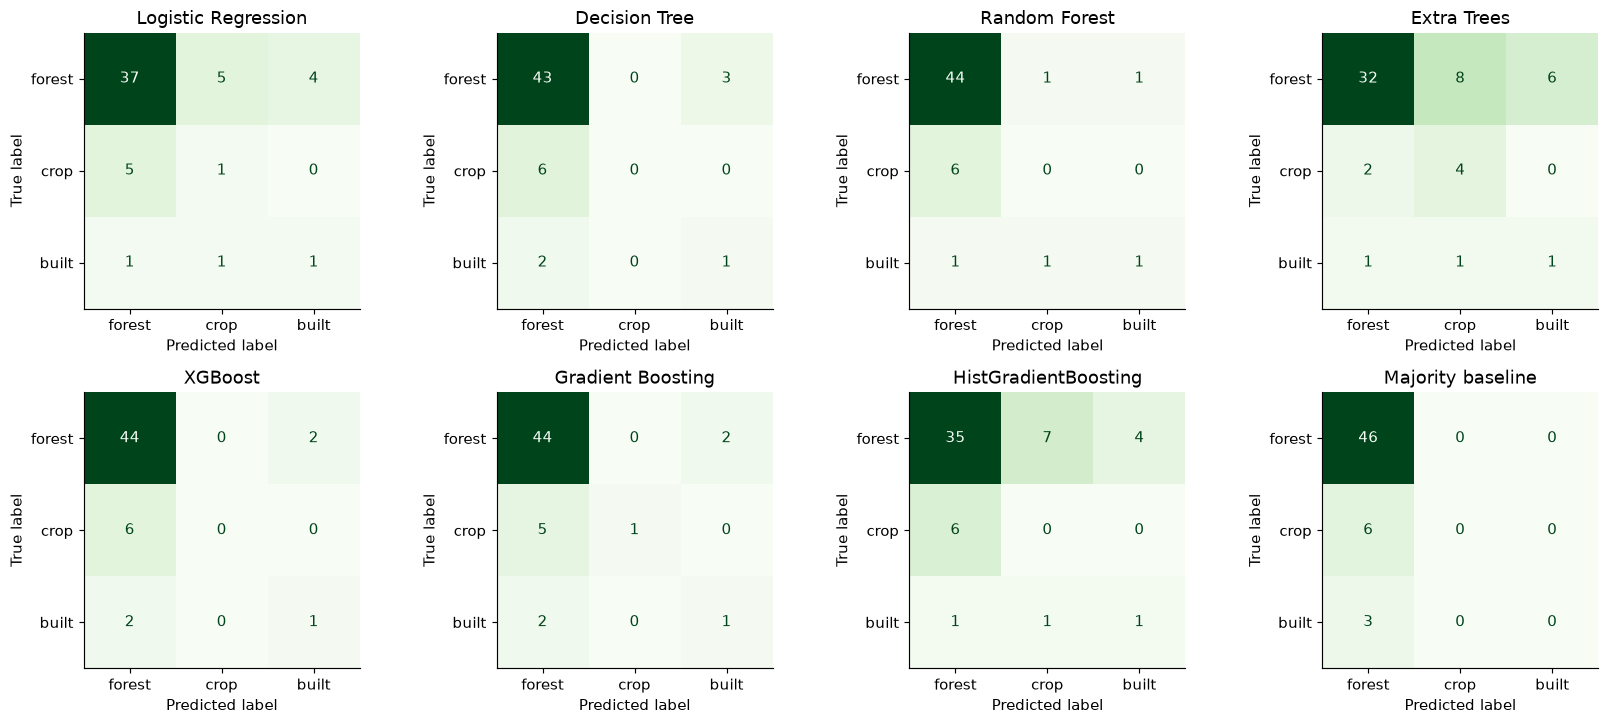

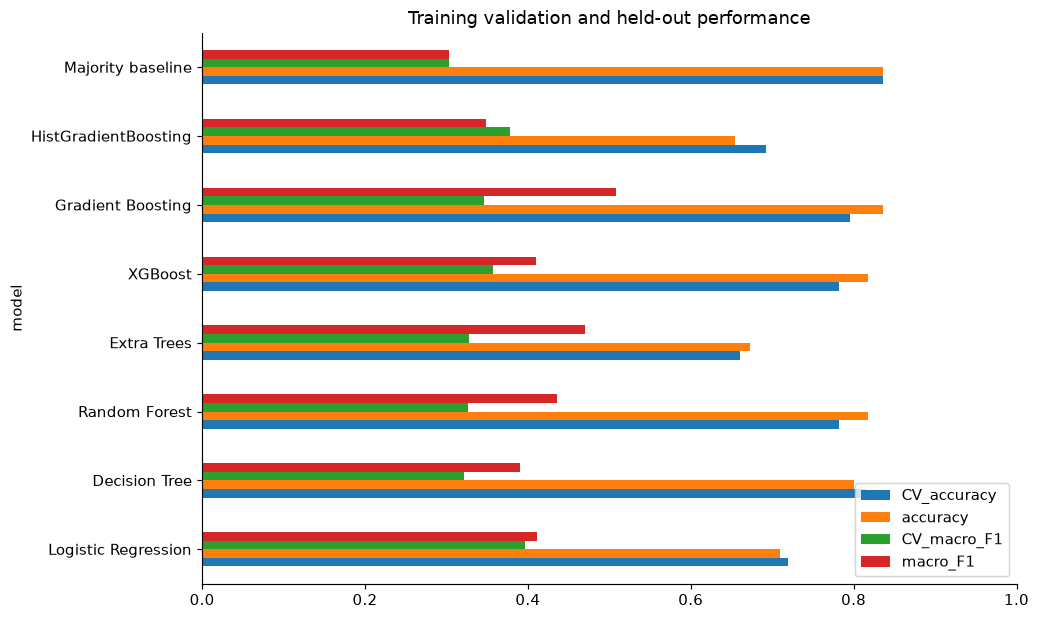

,accuracy,macro_F1
lower,0.6,0.265152
upper,0.8,0.592028


In [12]:
from sklearn.inspection import permutation_importance
rows, matrices, reports, predictions = [], {}, {}, {}
for name, recipe in recipes.items():
    t=perf_counter()
    fitted=clone(recipe).fit(X.loc[train], y.loc[train])
    fit_seconds=perf_counter()-t
    t=perf_counter()
    p=fitted.predict_proba(X.loc[test])
    inference_ms=1000*(perf_counter()-t)
    assert np.array_equal(fitted.classes_,codes)
    pred=p.argmax(axis=1)
    actual=y.loc[test]
    predictions[name]=p
    if name==best: winner=fitted
    reports[name]=classification_report(actual,pred,labels=codes,target_names=classes,output_dict=True,zero_division=0)
    matrices[name]=confusion_matrix(actual,pred,labels=codes)
    result={"model":name,"CV_accuracy":choices.loc[name,"mean_test_accuracy"],"CV_macro_F1":choices.loc[name,"mean_test_macro_F1"],
            "CV_macro_F1_SD":choices.loc[name,"std_test_macro_F1"],"train_macro_F1":f1_score(y.loc[train],fitted.predict(X.loc[train]),average="macro"),
            "accuracy":accuracy_score(actual,pred),"balanced_accuracy":balanced_accuracy_score(actual,pred),
            "macro_F1":f1_score(actual,pred,average="macro"),"weighted_F1":f1_score(actual,pred,average="weighted"),
            "macro_precision":precision_score(actual,pred,average="macro",zero_division=0),
            "macro_recall":recall_score(actual,pred,average="macro"),"macro_OVR_AUC":roc_auc_score(actual,p,multi_class="ovr"),
            "fit_seconds":fit_seconds,"inference_ms_55":inference_ms,"conversion_AP":average_precision_score(actual.ne(0),1-p[:,0]),
            **calibration_metrics(actual,p)}
    for k,label in enumerate(classes):
        result["AUC_"+label]=roc_auc_score(actual.eq(k),p[:,k])
        for metric in ("precision","recall"):
            result[metric+"_"+label]=reports[name][label][metric]
    rows.append(result)
metrics=pd.DataFrame(rows).set_index("model")
metrics.to_csv(artifacts/"held_out_model_comparison.csv")
(artifacts/"classification_reports.json").write_text(json.dumps(reports,indent=2))
(artifacts/"confusion_matrices.json").write_text(json.dumps({k:v.tolist() for k,v in matrices.items()},indent=2))
display(metrics.round(3))
fig,axes=plt.subplots(2,4,figsize=(16,7))
for ax,(name,cm) in zip(axes.flat,matrices.items()):
    ConfusionMatrixDisplay(cm,display_labels=["forest","crop","built"]).plot(ax=ax,colorbar=False,cmap="Greens")
    ax.set_title(name)
fig.tight_layout(); save_plot("confusion_matrices"); plt.show()
metrics[["CV_accuracy","accuracy","CV_macro_F1","macro_F1"]].plot.barh(figsize=(10,6),xlim=(0,1))
plt.title("Training validation and held-out performance"); plt.tight_layout(); save_plot("comparison"); plt.show()
prob=predictions[best]
rng=np.random.default_rng(SEED)
groups=[np.flatnonzero(actual.to_numpy()==k) for k in codes]
interval=[]
for _ in range(1500):
    draw=np.concatenate([rng.choice(g,len(g),replace=True) for g in groups])
    obs=actual.to_numpy()[draw]; predicted=prob[draw].argmax(axis=1)
    interval.append([np.mean(obs==predicted),f1_score(obs,predicted,average="macro")])
ci=pd.DataFrame(np.quantile(interval,[.025,.975],axis=0),index=["lower","upper"],columns=["accuracy","macro_F1"])
display(ci); ci.to_csv(artifacts/"test_bootstrap_intervals.csv")
pd.DataFrame(prob,index=forest.loc[test,"parcel_id"],columns=classes).assign(actual=np.array(classes)[actual]).to_csv(artifacts/"test_predictions.csv")
final_model=clone(recipes[best]).fit(X.loc[y.index],y)
def fit_model(name,ids):
    return clone(recipes[name]).fit(X.loc[ids],y.loc[ids])

## Feature importance and SHAP

Permutation importance measures a held-out drop in macro-F1. SHAP explains the full fitted pipeline on original predictor scales. The combined score and the two destination scores are explained against a fixed background. Positive SHAP values increase the corresponding score. These associations do not establish causes.

C:\Users\LENOVO\AppData\Local\Temp\forest_lab_311b\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


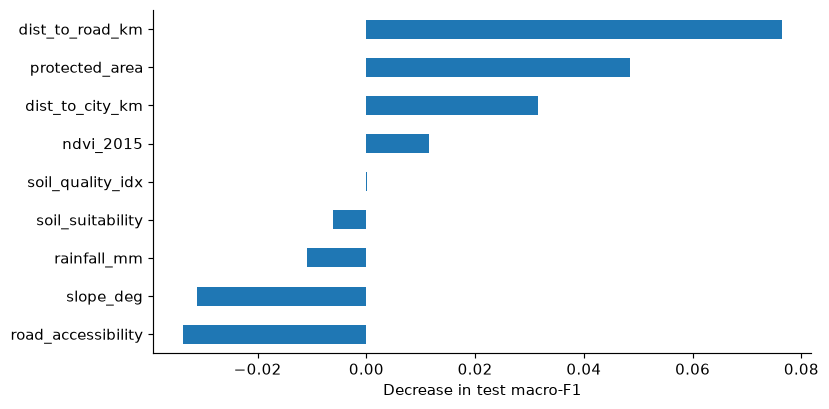

,conversion,agricultural,built_up
dist_to_road_km,0.137361,0.041013,0.108161
soil_suitability,0.126124,0.051346,0.074810
protected_area,0.099125,0.064004,0.035121
dist_to_city_km,0.080340,0.016379,0.084802
soil_quality_idx,0.064497,0.014633,0.050462
road_accessibility,0.060635,0.030090,0.031742
slope_deg,0.056411,0.031832,0.024671
rainfall_mm,0.017738,0.037296,0.053015
ndvi_2015,0.015570,0.053607,0.042562


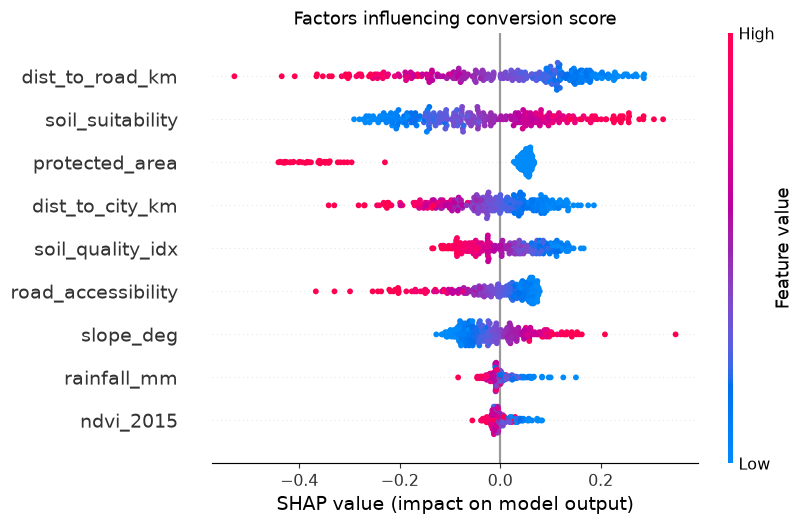

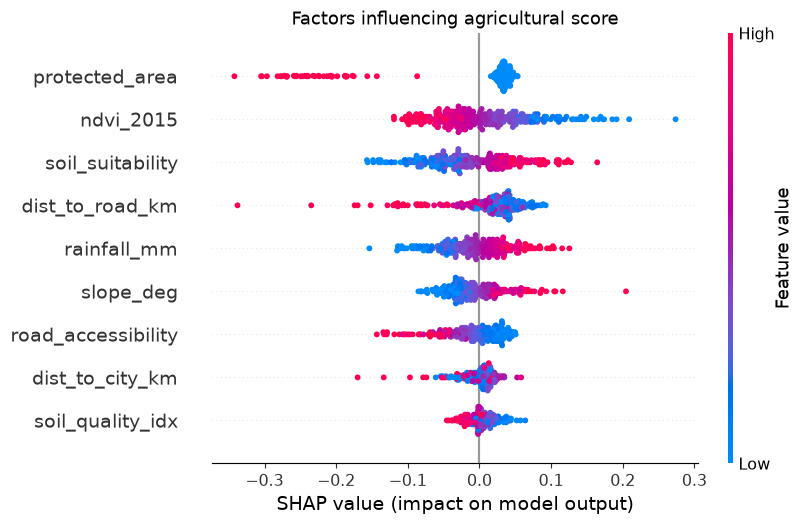

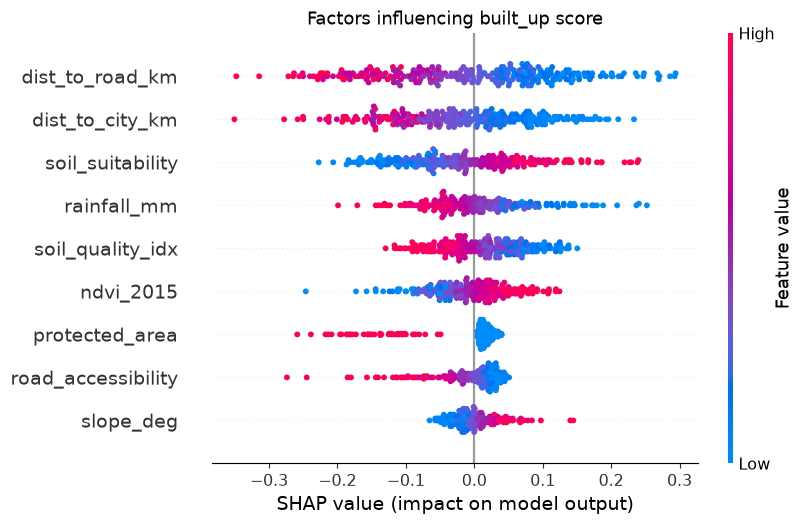

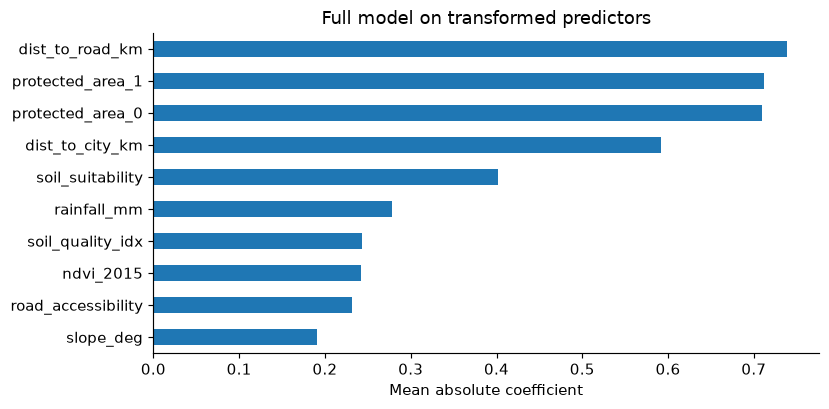

In [13]:
import shap
importance=permutation_importance(winner,X.loc[test],actual,n_repeats=20,random_state=SEED,
    scoring=make_scorer(f1_score,average="macro",zero_division=0))
perm=pd.Series(importance.importances_mean,index=features).sort_values()
perm.to_csv(artifacts/"permutation_importance.csv"); perm.plot.barh()
plt.xlabel("Decrease in test macro-F1"); plt.tight_layout(); save_plot("permutation_importance"); plt.show()
def explain_outputs(arr):
    frame=pd.DataFrame(arr,columns=features)
    frame[status]=frame[status].astype("Int64").astype("string").astype(object).where(frame[status].notna(),np.nan)
    p=final_model.predict_proba(frame)
    lookup={classes[int(k)]:i for i,k in enumerate(final_model.classes_)}
    return np.column_stack([1-p[:,lookup[classes[0]]],p[:,lookup[classes[1]]],p[:,lookup[classes[2]]]])
raw_matrix=X.loc[y.index].astype(float)
explainer=shap.Explainer(explain_outputs,raw_matrix.sample(32,random_state=SEED),algorithm="permutation",seed=SEED)
explanation=explainer(raw_matrix,max_evals=5*(2*len(features)+1))
np.testing.assert_allclose(explanation.base_values+explanation.values.sum(axis=1),explain_outputs(raw_matrix),atol=1e-5)
shap_table=pd.DataFrame(np.abs(explanation.values).mean(axis=0),index=features,columns=["conversion","agricultural","built_up"])
shap_table.to_csv(artifacts/"shap_importance.csv")
display(shap_table.sort_values("conversion",ascending=False))
for i,label in enumerate(shap_table.columns):
    shap.plots.beeswarm(explanation[:,:,i],show=False)
    plt.title("Factors influencing "+label+" score")
    plt.tight_layout(); save_plot("shap_"+label); plt.show()
# Native weights describe the fitted estimator's transformed input columns.
underlying = (final_model.calibrated_classifiers_[0].estimator if use_calibration else final_model)
est = underlying.named_steps["model"]
names = underlying.named_steps["prep"].get_feature_names_out()
if underlying.named_steps["reduce"] != "passthrough":
    names = underlying.named_steps["reduce"].get_feature_names_out()
values = est.feature_importances_ if hasattr(est,"feature_importances_") else np.abs(est.coef_).mean(axis=0)
native = pd.Series(values,index=names).sort_values()
native.rename("importance").to_csv(artifacts/"native_feature_importance.csv")
native.plot.barh()
plt.xlabel("Mean absolute coefficient" if hasattr(est,"coef_") else "Native feature importance")
plt.title("Full model on transformed predictors")
plt.tight_layout(); save_plot("native_importance"); plt.show()


## Out-of-Fold Risk Scoring

With model selection complete, use five new stratified folds over the full eligible set. Each parcel receives one prediction from a model trained on the other four folds. Out-of-scope parcels use the full-data fit. These historical scores are separate from the holdout accuracy estimate.

In [14]:
rank_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
p_all = pd.DataFrame(index=forest.index, columns=classes, dtype=float)
rank_fold = pd.Series(index=forest.index, dtype="Int64")
ids = y.index.to_numpy()
def named_probs(pipe, rows):
    arr = pipe.predict_proba(X.loc[rows])
    assert np.isfinite(arr).all()
    names = [classes[int(k)] for k in pipe.classes_]
    return pd.DataFrame(pipe.predict_proba(X.loc[rows]), index=rows, columns=names)[classes]

for fold, (a,b) in enumerate(rank_cv.split(ids, y), start=1):
    fit_ids, score_ids = ids[a], ids[b]
    assert set(fit_ids).isdisjoint(score_ids) and rank_fold.loc[score_ids].isna().all()
    fold_model = fit_model(best, fit_ids)
    p_all.loc[score_ids] = named_probs(fold_model, score_ids)
    rank_fold.loc[score_ids] = fold
outside = forest.index[~eligible]
assert len(outside) == 10 and set(outside).isdisjoint(ids)
assert rank_fold.loc[ids].value_counts().sort_index().tolist() == [55]*5
p_all.loc[outside] = named_probs(final_model, outside)
assert np.isfinite(p_all).all().all() and ((p_all >= 0) & (p_all <= 1)).all().all()
np.testing.assert_allclose(p_all.sum(axis=1), 1, atol=1e-6)
display(rank_fold.value_counts().sort_index().rename("eligible parcels scored"))

1    55
2    55
3    55
4    55
5    55
Name: eligible parcels scored, dtype: Int64

## Regional Risk Ranking

For each 2015 forest parcel, compare both conversion destinations and separately identify the most likely overall outcome. Low is below 0.33, Medium is 0.33 to below 0.66 and High is at least 0.66. These fixed thresholds screen uncalibrated model scores. The ten excluded destinations have scores under the three-class model only.

,region,baseline_year,target_year,observed_2025_land_cover,observed_transition,scope_status,prediction_method,risk_score,probability_no_change,probability_agricultural,probability_built_up,most_likely_conversion_type,most_likely_overall_outcome,risk_level
909,910,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.921720,0.078280,0.084118,0.837602,to_built_up,to_built_up,High
799,800,2015,2025,Built-up,Forest -> Built-up,in_scope,five_fold_out_of_fold,0.903360,0.096640,0.049841,0.853519,to_built_up,to_built_up,High
897,898,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.876036,0.123964,0.272873,0.603163,to_built_up,to_built_up,High
311,312,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.867679,0.132321,0.318230,0.549449,to_built_up,to_built_up,High
133,134,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.855020,0.144980,0.705604,0.149416,to_agricultural,to_agricultural,High
466,467,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.849722,0.150278,0.193929,0.655792,to_built_up,to_built_up,High
110,111,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.834360,0.165640,0.100428,0.733932,to_built_up,to_built_up,High
335,336,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.824350,0.175650,0.276533,0.547817,to_built_up,to_built_up,High
248,249,2015,2025,Built-up,Forest -> Built-up,in_scope,five_fold_out_of_fold,0.814939,0.185061,0.414332,0.400607,to_agricultural,to_agricultural,High
368,369,2015,2025,Cropland,Forest -> Cropland,in_scope,five_fold_out_of_fold,0.812582,0.187418,0.074158,0.738425,to_built_up,to_built_up,High


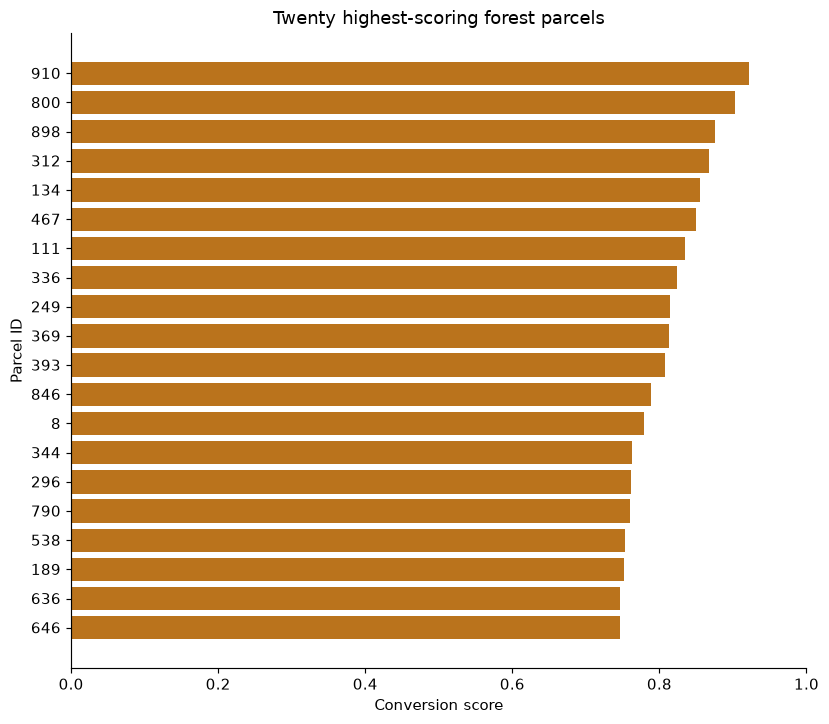

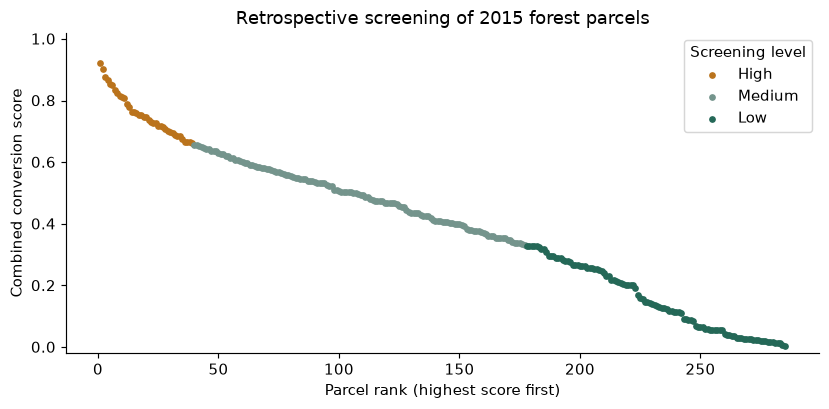

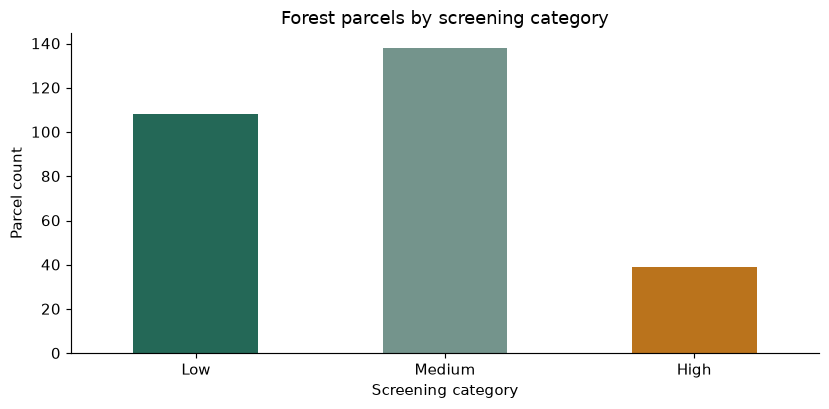

In [15]:
risk = pd.DataFrame({"region": forest.parcel_id, "baseline_year": 2015, "target_year": 2025,
    "observed_2025_land_cover": forest.land_use_2025,
    "observed_transition": forest.land_use_2015 + " -> " + forest.land_use_2025,
    "scope_status": np.where(eligible, "in_scope", "outside_scope"),
    "prediction_method": np.where(eligible, "five_fold_out_of_fold", "full_275_model"),
    "risk_score": 1 - p_all.no_change, "probability_no_change": p_all.no_change,
    "probability_agricultural": p_all.to_agricultural, "probability_built_up": p_all.to_built_up,
    "most_likely_conversion_type": p_all[classes[1:]].idxmax(axis=1),
    "most_likely_overall_outcome": p_all.idxmax(axis=1)})
risk["risk_level"] = pd.cut(risk.risk_score, [-np.inf, .33, .66, np.inf], labels=["Low","Medium","High"], right=False)
risk = risk.sort_values(["risk_score","region"], ascending=[False,True])
display(risk.head(10))
top = risk.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8,7))
ax.barh(top.region.tolist(), top.risk_score, color=colors[1])
ax.set(xlim=(0,1), xlabel="Conversion score", ylabel="Parcel ID", title="Twenty highest-scoring forest parcels")
fig.tight_layout()
save_plot("13_top_20_parcels")
plt.show()
fig, ax = plt.subplots()
for level, color in zip(["High", "Medium", "Low"], [colors[1], "#74948c", colors[0]]):
    mask = risk.risk_level.eq(level)
    ax.scatter(np.arange(1, len(risk)+1)[mask], risk.loc[mask, "risk_score"], s=13, label=level, color=color)
ax.set(xlabel="Parcel rank (highest score first)", ylabel="Combined conversion score",
       ylim=(-.02, 1.02), title="Retrospective screening of 2015 forest parcels")
ax.legend(title="Screening level")
plt.tight_layout()
save_plot("09_ranked_parcel_risk")
plt.show()
fig, ax = plt.subplots()
risk.risk_level.value_counts().reindex(["Low", "Medium", "High"], fill_value=0).plot.bar(
    ax=ax, color=[colors[0], "#74948c", colors[1]], rot=0)
ax.set(title="Forest parcels by screening category", xlabel="Screening category", ylabel="Parcel count")
plt.tight_layout()
save_plot("10_screening_categories")
plt.show()

## Export Model and CSV

Save the fitted 275-parcel pipeline directly with joblib. It accepts a pandas DataFrame with the nine documented features, including the two deterministic proxies and string-valued protected status. Reload it and verify its probabilities against the in-memory fit. Verify the ranked CSV independently after reading it back.

In [16]:
from datetime import datetime, timezone
import shutil
execution = datetime.now(timezone.utc).isoformat()
versions = {p: metadata.version(p) for p in ["numpy","pandas","scikit-learn","xgboost","matplotlib","shap","joblib"]}
manifest = {"model_name": best, "model_parameters": {k:str(v) for k,v in choices.loc[best,"params"].items()},
    "class_labels":classes, "sigmoid_calibrated":use_calibration, "inference_module":"forest_pipeline.py",
    "execution_date_utc": execution, "seed": SEED, "source_sha256": source_hash, "versions": versions,
    "feature_order": features, "numeric_features": numeric, "categorical_features": {status:"string, e.g. '0' or '1', or np.nan"},
    "feature_recipes": {"soil_suitability":"clip(soil_quality_idx * (1 - slope_deg/45), 0, 1)",
                        "road_accessibility":"1 / (1 + dist_to_road_km)"},
    "target_class_labels": {str(int(k)):classes[int(k)] for k in final_model.classes_},
    "rows": {"source":len(df),"forest":len(forest),"eligible_full_fit":len(y),"outside_scope":len(outside),
             "evaluation_train":len(train),"evaluation_test":len(test)},
    "risk_thresholds":{"medium_min":.33,"high_min":.66},
    "assumptions":["Undated distances, rainfall and protection describe baseline conditions; soil and slope are sufficiently static.",
                   "Population growth timing is unknown and this field is excluded."],
    "limitations":["One observed decade; temporal and spatial transfer untested.","Built-up has 16 examples and combines development types.",
                   "Class-weighted scores are uncalibrated. The target excludes grassland and barren destinations."],
    "artifact_fit":"All 275 eligible parcels. Only the ten outside-scope ranking rows use this model.",
    "ranking_fit":"Five-fold out-of-fold predictions for the 275 eligible parcels."}
model_path = Path("forest_conversion_model.joblib")
joblib.dump(final_model, model_path, compress=3)
metadata_path = Path("forest_conversion_model_metadata.json")
metadata_path.write_text(json.dumps(manifest, indent=2, allow_nan=False), encoding="utf-8")
loaded = joblib.load(model_path)
np.testing.assert_allclose(loaded.predict_proba(X[features]), final_model.predict_proba(X[features]))
np.testing.assert_allclose(named_probs(loaded,outside), p_all.loc[outside])
risk_path = Path("forest_conversion_risk.csv")
risk.to_csv(risk_path, index=False)
saved = pd.read_csv(risk_path, dtype={"region":"string"})
assert len(saved) == saved.region.nunique() == 285 and set(saved.region) == set(forest.parcel_id)
assert saved.risk_score.is_monotonic_decreasing
probs = saved[["probability_no_change","probability_agricultural","probability_built_up"]]
assert np.isfinite(probs).all().all() and ((probs >= 0) & (probs <= 1)).all().all()
np.testing.assert_allclose(probs.sum(axis=1), 1, atol=1e-6)
np.testing.assert_allclose(saved.risk_score, 1 - saved.probability_no_change, atol=1e-7)
np.testing.assert_allclose(saved.risk_score, saved.probability_agricultural + saved.probability_built_up, atol=1e-6)
assert set(saved.loc[saved.scope_status.eq("outside_scope"), "region"]) == set(forest.loc[outside,"parcel_id"])
assert hashlib.sha256(path.read_bytes()).hexdigest() == source_hash
audit = risk.assign(ranking_fold=rank_fold.reindex(risk.index))
audit.to_csv(artifacts / "risk_scope_and_provenance.csv", index=False)
risk.loc[risk.risk_level.eq("High")].head(10).to_csv(artifacts / "top_high_risk_parcels.csv", index=False)
shutil.copyfile(model_path, artifacts / model_path.name)
shutil.copyfile(metadata_path, artifacts / "model_manifest.json")
checks = {"verified_at":execution, "rows":len(saved), "unique_ids":saved.region.nunique(),
          "outside_scope":len(outside), "source_hash_verified":True, "model_reload_verified":True,
          "five_disjoint_scoring_folds_verified":True, "probability_checks_passed":True,
          "SHAP_additivity_verified":True, "exported_plot_count":len(list(plots.glob("*.png")))}
(artifacts / "verification.json").write_text(json.dumps(checks, indent=2), encoding="utf-8")
display(checks)
# Keep the seven training-selected family configurations available for comparison.
family_dir = artifacts / "fitted_families"
family_dir.mkdir(exist_ok=True)
for family_name in families:
    if family_name == "Majority baseline":
        continue
    family_model = final_model if family_name == best else fit_model(family_name, y.index)
    filename = family_name.lower().replace(" ","_") + ".joblib"
    joblib.dump(family_model, family_dir / filename, compress=3)


{'verified_at': '2026-11-03T07:14:00.243197+00:00',
 'rows': 285,
 'unique_ids': 285,
 'outside_scope': 10,
 'source_hash_verified': True,
 'model_reload_verified': True,
 'five_disjoint_scoring_folds_verified': True,
 'probability_checks_passed': True,
 'SHAP_additivity_verified': True,
 'exported_plot_count': 14}

## Monitoring reference

Record baseline distributions and the expected schema using eligible parcels. Run monitor.py on a later batch with the same units and schema. Its distribution comparisons flag shifts for review. Performance drift needs observed follow-up labels and comparable horizons. The project has no live data feed.

In [17]:

reference = {"numeric":{}, "protected_status_frequency":X.loc[y.index,status].value_counts(normalize=True).to_dict(),
             "missing_fraction":X.loc[y.index].isna().mean().to_dict()}
for col in numeric:
    v=X.loc[y.index,col].dropna()
    edges=np.unique(v.quantile([.2,.4,.6,.8]).to_numpy())
    counts=np.histogram(v,bins=np.r_[-np.inf,edges,np.inf])[0]
    reference["numeric"][col]={"cuts":edges.tolist(),"frequency":(counts/counts.sum()).tolist()}
Path("monitoring_reference.json").write_text(json.dumps(reference,indent=2))


2419

## Results and limitations

Use the fixed holdout only for reporting. The winning family is chosen before test scores are calculated.

In [18]:
def md_table(frame):
    # Format a small table without an optional Markdown library.
    def cell(v):
        return f"{v:.3f}" if isinstance(v, (float,np.floating)) else str(v)
    rows = [frame.columns.tolist(), ["---"] * len(frame.columns), *frame.itertuples(index=False,name=None)]
    return "\n".join("| " + " | ".join(cell(v) for v in row) + " |" for row in rows)


r=metrics.loc[best]
baseline=metrics.loc["Majority baseline"]
compact=metrics[["CV_accuracy","CV_macro_F1","accuracy","balanced_accuracy","macro_precision","macro_F1","weighted_F1","macro_OVR_AUC"]].reset_index()
counts=risk.risk_level.value_counts()
report=f"""# Forest conversion benchmark

## Data and prediction target

The only source was land_use_change.csv with {len(df)} parcels. The 285 forest parcels ended as forest (230), cropland (29), built-up (16), grassland (8) or barren (2). The first three classes define the model. Ten outside-scope parcels appear in the ranking only. Built-up cannot be divided into residential and industrial. Neither the outcome nor the model measures sustainability.

Soil suitability combines quality and slope. Road accessibility uses distance to roads. Population growth timing is unknown and excluded. Agricultural destination is observed but agricultural activity history and infrastructure change are unavailable. Undated baseline inputs are assumed sufficiently static. Fold-local preprocessing handles missing values and categoricals.

## Experiment and results

Seven classifiers and the majority reference used identical validation splits. Each of 84 learned configurations was evaluated across 12 training folds. Model fitting, optional PCA, and class balancing used training-fold rows only. The winning family was **{best}**, with training-selected settings `{choices.loc[best,"params"]}`. Sigmoid calibration selected: {use_calibration}. This is an exploratory search on 220 parcels. CV selection scores can be optimistic. The 55-parcel holdout was also used for reporting in earlier iterations and is not independent confirmation.

{md_table(compact)}

The winner correctly classified {int(round(r.accuracy*len(test)))} of {len(test)} parcels. The majority rule accuracy was {baseline.accuracy:.1%}. The earlier project XGBoost had 54.5% accuracy and 0.329 macro-F1 on the same split. The earlier accuracy-focused trial reached 81.8% with zero correct agricultural or built-up classifications.

{md_table(pd.DataFrame({k:reports[best][k] for k in classes}).T.rename_axis("outcome").reset_index())}

Conditional stratified bootstrap 95% intervals: accuracy {ci.accuracy.iloc[0]:.3f} to {ci.accuracy.iloc[1]:.3f}, macro-F1 {ci.macro_F1.iloc[0]:.3f} to {ci.macro_F1.iloc[1]:.3f}. Only three test parcels became built-up. Intervals omit training and selection uncertainty. Model timings and the training-to-test performance gaps are in the benchmark CSV.

## Model interpretation and screening

The highest mean absolute conversion SHAP contributions were {", ".join(shap_table.conversion.nlargest(3).index)}. The fitted pipelines for every family appear in forest_conversion_results/fitted_families. Their full-data fits are for inference only. The benchmark table reports the evaluation fits. Separate plots explain agricultural and built-up scores. They describe model behaviour. They do not identify causes.

There are {counts.get("High",0)} High, {counts.get("Medium",0)} Medium and {counts.get("Low",0)} Low scores. Fixed thresholds are 0.66 and 0.33. Each eligible parcel was scored outside its fitting fold. The ten outside-scope parcels use the full-data fit. Probabilities are conditional on the three-class task and retrospective; generalisation to future years is untested.

{md_table(risk.head(10)[["region","risk_score","observed_2025_land_cover","most_likely_conversion_type"]])}

The model bundle needs forest_pipeline.py on the Python path. Use monitor.py with incoming baseline batches to compare feature distributions and, when mature observed outcomes are supplied, evaluate class performance. New independent outcomes are needed for prospective validation.
"""
Path("forest_conversion_final_report.md").write_text(report,encoding="utf-8")
display(Markdown(report))


# Forest conversion benchmark

## Data and prediction target

The only source was land_use_change.csv with 1000 parcels. The 285 forest parcels ended as forest (230), cropland (29), built-up (16), grassland (8) or barren (2). The first three classes define the model. Ten outside-scope parcels appear in the ranking only. Built-up cannot be divided into residential and industrial. Neither the outcome nor the model measures sustainability.

Soil suitability combines quality and slope. Road accessibility uses distance to roads. Population growth timing is unknown and excluded. Agricultural destination is observed but agricultural activity history and infrastructure change are unavailable. Undated baseline inputs are assumed sufficiently static. Fold-local preprocessing handles missing values and categoricals.

## Experiment and results

Seven classifiers and the majority reference used identical validation splits. Each of 84 learned configurations was evaluated across 12 training folds. Model fitting, optional PCA, and class balancing used training-fold rows only. The winning family was **Logistic Regression**, with training-selected settings `{'model__C': 1.0, 'reduce': 'passthrough', 'weight_power': 0.65}`. Sigmoid calibration selected: False. This is an exploratory search on 220 parcels. CV selection scores can be optimistic. The 55-parcel holdout was also used for reporting in earlier iterations and is not independent confirmation.

| model | CV_accuracy | CV_macro_F1 | accuracy | balanced_accuracy | macro_precision | macro_F1 | weighted_F1 | macro_OVR_AUC |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic Regression | 0.720 | 0.396 | 0.709 | 0.435 | 0.401 | 0.412 | 0.726 | 0.744 |
| Decision Tree | 0.815 | 0.322 | 0.800 | 0.423 | 0.364 | 0.391 | 0.757 | 0.618 |
| Random Forest | 0.782 | 0.326 | 0.818 | 0.430 | 0.454 | 0.436 | 0.781 | 0.708 |
| Extra Trees | 0.661 | 0.328 | 0.673 | 0.565 | 0.455 | 0.470 | 0.718 | 0.783 |
| XGBoost | 0.782 | 0.357 | 0.818 | 0.430 | 0.393 | 0.410 | 0.769 | 0.734 |
| Gradient Boosting | 0.795 | 0.347 | 0.836 | 0.486 | 0.732 | 0.509 | 0.808 | 0.734 |
| HistGradientBoosting | 0.692 | 0.378 | 0.655 | 0.365 | 0.344 | 0.348 | 0.679 | 0.686 |
| Majority baseline | 0.836 | 0.304 | 0.836 | 0.333 | 0.279 | 0.304 | 0.762 | 0.500 |

The winner correctly classified 39 of 55 parcels. The majority rule accuracy was 83.6%. The earlier project XGBoost had 54.5% accuracy and 0.329 macro-F1 on the same split. The earlier accuracy-focused trial reached 81.8% with zero correct agricultural or built-up classifications.

| outcome | precision | recall | f1-score | support |
| --- | --- | --- | --- | --- |
| no_change | 0.860 | 0.804 | 0.831 | 46.000 |
| to_agricultural | 0.143 | 0.167 | 0.154 | 6.000 |
| to_built_up | 0.200 | 0.333 | 0.250 | 3.000 |

Conditional stratified bootstrap 95% intervals: accuracy 0.600 to 0.800, macro-F1 0.265 to 0.592. Only three test parcels became built-up. Intervals omit training and selection uncertainty. Model timings and the training-to-test performance gaps are in the benchmark CSV.

## Model interpretation and screening

The highest mean absolute conversion SHAP contributions were dist_to_road_km, soil_suitability, protected_area. The fitted pipelines for every family appear in forest_conversion_results/fitted_families. Their full-data fits are for inference only. The benchmark table reports the evaluation fits. Separate plots explain agricultural and built-up scores. They describe model behaviour. They do not identify causes.

There are 39 High, 138 Medium and 108 Low scores. Fixed thresholds are 0.66 and 0.33. Each eligible parcel was scored outside its fitting fold. The ten outside-scope parcels use the full-data fit. Probabilities are conditional on the three-class task and retrospective; generalisation to future years is untested.

| region | risk_score | observed_2025_land_cover | most_likely_conversion_type |
| --- | --- | --- | --- |
| 910 | 0.922 | Forest | to_built_up |
| 800 | 0.903 | Built-up | to_built_up |
| 898 | 0.876 | Forest | to_built_up |
| 312 | 0.868 | Forest | to_built_up |
| 134 | 0.855 | Forest | to_agricultural |
| 467 | 0.850 | Forest | to_built_up |
| 111 | 0.834 | Forest | to_built_up |
| 336 | 0.824 | Forest | to_built_up |
| 249 | 0.815 | Built-up | to_agricultural |
| 369 | 0.813 | Cropland | to_built_up |

The model bundle needs forest_pipeline.py on the Python path. Use monitor.py with incoming baseline batches to compare feature distributions and, when mature observed outcomes are supplied, evaluate class performance. New independent outcomes are needed for prospective validation.
